# 02 — Within-dataset versus cross-dataset performance (Experiment 2)

**Question 2.** How much does classification performance change when moving from evaluation within Dataset 1 to evaluation on held-out Dataset 2? A drop is plausible, but this notebook reports whichever direction is actually found.

**Why nested cross-validation?** Experiment 1 chose its settings by 5-fold cross-validation on Dataset 1. Its best selection score (≈ 0.635) is optimistic, because those same scores decided the settings. A fair internal estimate needs nested cross-validation: settings are chosen inside each outer training split, and the outer test fold is used only once, for scoring.

**What this compares.** Each outer-fold model trains on about 60 participants, while the external model from Experiment 1 trains on all 75. So this compares the same **model-development procedure** under internal and external evaluation, not one identical fitted model. Sample composition, sample size, acquisition and exclusions all differ between the datasets, and the analysis cannot isolate a single cause of any gap.

**Context.** Dataset 2 results were already examined in Experiment 1, so this is an exploratory follow-up. No ID appears in both datasets, but person-level independence is unconfirmed. Dataset 1 includes ten participants from acquisition 2, so dataset membership is not the same as acquisition membership.

Inputs: the frozen 110-participant preprocessing (`outputs/frozen_preprocessing_2026-11-16_124625_EST`) and the revised Experiment 1 outputs (`outputs/experiment_1_revised`). Neither is modified. Run all cells in order with the `.venv` kernel.

In [1]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (roc_auc_score, accuracy_score, balanced_accuracy_score,
                             confusion_matrix)
from IPython.display import display, Markdown

PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "outputs").is_dir() and (p / "data").is_dir())
FROZEN = PROJECT / "outputs/frozen_preprocessing_2026-11-16_124625_EST"
EXPERIMENT_1 = PROJECT / "outputs/experiment_1_revised"
OUTPUT = PROJECT / "outputs/experiment_2"
OUTPUT.mkdir(parents=True, exist_ok=True)

FEATURES = ["relative_delta", "relative_theta", "relative_alpha", "relative_beta"]
LABEL_CODES = {"Control": 0, "Psychosis": 1}  # source label "Psychosis" = first-episode psychosis
C_VALUES = [0.1, 1, 10]
CLASS_WEIGHTS = [None, "balanced"]
N_FOLDS = 5
OUTER_SEEDS = [101, 202, 303, 404, 505]  # fixed before running; each repeat's inner folds use the same seed
THRESHOLD = 0.50
print("Python", platform.python_version(), "| scikit-learn", version("scikit-learn"))

Python 3.14.7 | scikit-learn 1.9.1


## 1. Load and check the frozen sample and Experiment 1 outputs

The feature tables and participant QC are checked against the frozen SHA-256 manifest. The notebook then confirms the expected counts (Dataset 1: 29 Control / 46 Psychosis; Dataset 2: 14 / 21), unique IDs with no overlap, valid labels, four finite features, and agreement with the inclusion inventory. Experiment 1's files have no manifest, so their SHA-256 values are recorded in this notebook's settings output.

In [2]:
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


manifest = json.loads((FROZEN / "sha256_manifest.json").read_text())["sha256"]
input_files = {name: FROZEN / name for name in ["master_preprocessing/resting-task-1_features.csv",
                                                "master_preprocessing/resting-task-2_features.csv",
                                                "master_preprocessing/participant_qc.csv"]}
for name, path in input_files.items():
    assert sha256(path) == manifest[name], f"{name} does not match the frozen manifest"
dataset_1, dataset_2, qc = (pd.read_csv(path) for path in input_files.values())

for name, table, expected in [("resting-task-1", dataset_1, {"Control": 29, "Psychosis": 46}),
                              ("resting-task-2", dataset_2, {"Control": 14, "Psychosis": 21})]:
    assert table.dataset.eq(name).all() and not table.participant_id.duplicated().any()
    assert table.diagnosis.value_counts().to_dict() == expected
    assert all(pd.api.types.is_numeric_dtype(table[c]) for c in FEATURES)
    assert np.isfinite(table[FEATURES].to_numpy()).all()
    included = qc[(qc.dataset == name) & qc.included].set_index("participant_id")
    assert set(table.participant_id) == set(included.index)
    assert (table.set_index("participant_id").diagnosis == included.diagnosis.loc[table.participant_id]).all()
assert not set(dataset_1.participant_id) & set(dataset_2.participant_id)

experiment_1_files = {name: EXPERIMENT_1 / name for name in
                      ["test_predictions.csv", "test_metrics.csv", "selected_settings.json", "experiment_settings.json"]}
input_hashes = {str(p.relative_to(PROJECT)): sha256(p) for p in [*input_files.values(), *experiment_1_files.values()]}

X = dataset_1[FEATURES].to_numpy()
y = dataset_1.diagnosis.map(LABEL_CODES).to_numpy()
participant_ids = dataset_1.participant_id.to_numpy()
print("Dataset 1:", len(y), "participants;", int((y == 0).sum()), "controls,", int((y == 1).sum()), "psychosis")

Dataset 1: 75 participants; 29 controls, 46 psychosis


## 2. Nested cross-validation within Dataset 1

The pipeline (`StandardScaler` → L2 logistic regression, `l1_ratio=0.0`, `solver="lbfgs"`, `max_iter=1000`) and the grid (C ∈ {0.1, 1, 10} × class_weight ∈ {None, "balanced"}) are the same as in revised Experiment 1.

- **Outer loop:** shuffled stratified 5-fold, repeated with seeds 101, 202, 303, 404 and 505.
- **Inner loop:** shuffled stratified 5-fold *within the outer training split only*, using the same seed as its repeat. Each candidate is scored by mean inner ROC-AUC. **Tie-break (from Experiment 1):** highest mean AUC rounded to 10 decimals, then smaller C, then `None` before `"balanced"`.
- The selected pipeline is refitted on the whole outer training split and predicts the outer test fold.

Scaling is always inside the pipeline, so it is fitted only on whichever training data the current step uses. The outer test fold is never used for scaling, selection or fitting.

In [3]:
def make_model(C, class_weight):
    return Pipeline([
        ("scale", StandardScaler()),
        ("logistic", LogisticRegression(l1_ratio=0.0, C=C, class_weight=class_weight,
                                        solver="lbfgs", max_iter=1000)),
    ])


def choose_settings(X_train, y_train, seed):
    """Inner CV on the outer training split only; returns the chosen settings and all candidate scores."""
    inner_folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    rows = [{"C": C, "class_weight": str(weight),
             "mean_inner_auc": cross_val_score(make_model(C, weight), X_train, y_train,
                                               cv=inner_folds, scoring="roc_auc").mean()}
            for C in C_VALUES for weight in CLASS_WEIGHTS]
    scores = pd.DataFrame(rows)
    ranked = scores.assign(rounded=scores.mean_inner_auc.round(10), weighted=scores.class_weight.ne("None"))
    best = ranked.sort_values(["rounded", "C", "weighted"], ascending=[False, True, True]).iloc[0]
    return {"C": float(best.C), "class_weight": None if best.class_weight == "None" else best.class_weight,
            "mean_inner_auc": float(best.mean_inner_auc)}, scores


prediction_rows, fold_rows, inner_rows = [], [], []
for repeat, seed in enumerate(OUTER_SEEDS, start=1):
    outer_folds = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
    for fold, (train_index, test_index) in enumerate(outer_folds.split(X, y), start=1):
        train_ids, test_ids = set(participant_ids[train_index]), set(participant_ids[test_index])
        assert not train_ids & test_ids
        # Inner splits contain only outer-training participants.
        inner = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=seed)
        for inner_fit, inner_val in inner.split(X[train_index], y[train_index]):
            assert set(participant_ids[train_index][np.r_[inner_fit, inner_val]]) <= train_ids

        settings, inner_scores = choose_settings(X[train_index], y[train_index], seed)
        model = make_model(settings["C"], settings["class_weight"]).fit(X[train_index], y[train_index])
        assert np.allclose(model.named_steps["scale"].mean_, X[train_index].mean(axis=0))
        assert list(model.classes_) == [0, 1]
        probability = model.predict_proba(X[test_index])[:, 1]

        prediction_rows += [{"repeat": repeat, "seed": seed, "outer_fold": fold, "participant_id": pid,
                             "diagnosis": dataset_1.diagnosis.iloc[i], "true_label": y[i],
                             "probability_psychosis": p, "predicted_label": int(p >= THRESHOLD)}
                            for i, pid, p in zip(test_index, participant_ids[test_index], probability)]
        fold_rows.append({"repeat": repeat, "seed": seed, "outer_fold": fold, "n_train": len(train_index),
                          "n_test": len(test_index), "test_control": int((y[test_index] == 0).sum()),
                          "test_psychosis": int((y[test_index] == 1).sum()),
                          "selected_C": settings["C"], "selected_class_weight": str(settings["class_weight"]),
                          "selected_mean_inner_auc": settings["mean_inner_auc"],
                          "outer_fold_auc": roc_auc_score(y[test_index], probability)})
        inner_rows.append(inner_scores.assign(repeat=repeat, outer_fold=fold))

oof = pd.DataFrame(prediction_rows)
folds = pd.DataFrame(fold_rows)
inner_scores_all = pd.concat(inner_rows, ignore_index=True)

# Every Dataset 1 participant gets exactly one outer-test prediction per repeat.
assert (oof.groupby("repeat").participant_id.apply(lambda s: s.is_unique and set(s) == set(participant_ids))).all()
display(folds.pivot(index="repeat", columns="outer_fold", values="outer_fold_auc").round(3))
display(folds.groupby(["selected_C", "selected_class_weight"]).size().rename("outer folds").to_frame())

outer_fold,1,2,3,4,5
repeat,,,,,
1,0.704,0.778,0.611,0.537,0.28
2,0.537,0.778,0.463,0.556,0.82
3,0.778,0.593,0.556,0.630,0.74
4,0.852,0.481,0.648,0.481,0.44
5,0.481,0.500,0.630,0.796,0.70


outer folds
selected_C selected_class_weight             
0.1        None                             9
           balanced                         3
1.0        None                             6
           balanced                         2
10.0       None                             3
           balanced                         2

## 3. Internal performance

- **Internal AUC for a repeat:** the mean of its five outer-fold AUCs, with AUC computed separately within each fold.
- **Threshold metrics (0.50):** balanced accuracy, sensitivity, specificity and accuracy, computed from that repeat's complete out-of-fold predictions (each participant once).

The summary is the mean over the five repeats. Predictions from different repeats are **not** pooled, since they are the same 75 participants re-used, not extra people. The spread across folds and repeats is shown as split variability. It is not a confidence interval.

In [4]:
def threshold_metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sensitivity, specificity = tp / (tp + fn), tn / (tn + fp)
    assert np.isclose(balanced_accuracy_score(y_true, y_pred), (sensitivity + specificity) / 2)
    return {"balanced_accuracy": (sensitivity + specificity) / 2, "sensitivity": sensitivity,
            "specificity": specificity, "accuracy": accuracy_score(y_true, y_pred),
            "true_negative": tn, "false_positive": fp, "false_negative": fn, "true_positive": tp}


repeats = pd.DataFrame([{"repeat": r, "seed": OUTER_SEEDS[r - 1],
                         "internal_auc": folds.loc[folds.repeat == r, "outer_fold_auc"].mean(),
                         "fold_auc_min": folds.loc[folds.repeat == r, "outer_fold_auc"].min(),
                         "fold_auc_max": folds.loc[folds.repeat == r, "outer_fold_auc"].max(),
                         **threshold_metrics(g.true_label, g.predicted_label)}
                        for r, g in oof.groupby("repeat")])
internal = repeats[["internal_auc", "balanced_accuracy", "sensitivity", "specificity", "accuracy"]].mean()
display(repeats.round(3))
print("Mean over repeats:", internal.round(3).to_dict())

,repeat,seed,internal_auc,fold_auc_min,fold_auc_max,balanced_accuracy,sensitivity,specificity,accuracy,true_negative,false_positive,false_negative,true_positive
0,1,101,0.582,0.280,0.778,0.501,0.761,0.241,0.560,7,22,11,35
1,2,202,0.631,0.463,0.820,0.518,0.761,0.276,0.573,8,21,11,35
2,3,303,0.659,0.556,0.778,0.594,0.913,0.276,0.667,8,21,4,42
3,4,404,0.581,0.440,0.852,0.548,0.717,0.379,0.587,11,18,13,33
4,5,505,0.621,0.481,0.796,0.611,0.739,0.483,0.640,14,15,12,34


Mean over repeats: {'internal_auc': 0.615, 'balanced_accuracy': 0.555, 'sensitivity': 0.778, 'specificity': 0.331, 'accuracy': 0.605}


## 4. External performance (reused from Experiment 1)

The external result comes from the revised Experiment 1 primary model: C = 0.1, no class weighting, chosen within Dataset 1 and fitted on all 75 participants. It is **not** re-selected or refitted here. The notebook checks that the saved predictions reproduce the reported AUC and belong to the same frozen Dataset 2 participants and labels. The bootstrap interval is taken from Experiment 1's saved metrics.

In [5]:
external_predictions = pd.read_csv(EXPERIMENT_1 / "test_predictions.csv").query("analysis_version == 'primary_110'")
external_metrics = pd.read_csv(EXPERIMENT_1 / "test_metrics.csv", keep_default_na=False).set_index("analysis_version").loc["primary_110"]
assert external_predictions.participant_id.tolist() == dataset_2.participant_id.tolist()
assert (external_predictions.true_label.to_numpy() == dataset_2.diagnosis.map(LABEL_CODES).to_numpy()).all()
external_auc = roc_auc_score(external_predictions.true_label, external_predictions.probability_psychosis)
assert np.isclose(external_auc, external_metrics.roc_auc)
external = {"external_auc": external_auc, "ci_low": float(external_metrics.roc_auc_ci_low),
            "ci_high": float(external_metrics.roc_auc_ci_high),
            **threshold_metrics(external_predictions.true_label, external_predictions.predicted_label)}
assert np.isclose(external["balanced_accuracy"], float(external_metrics.balanced_accuracy))
print({k: round(float(v), 3) for k, v in external.items()})

{'external_auc': 0.497, 'ci_low': 0.289, 'ci_high': 0.704, 'balanced_accuracy': 0.548, 'sensitivity': 0.952, 'specificity': 0.143, 'accuracy': 0.629, 'true_negative': 2.0, 'false_positive': 12.0, 'false_negative': 1.0, 'true_positive': 20.0}


## 5. Generalization gap

**Generalization gap = mean nested-CV internal AUC − Dataset 2 AUC.** A positive value means lower external performance, and a negative value means higher. The gap is also shown for each repeat, to illustrate split variability. This is a descriptive comparison: no p-value or significance claim is made, because a valid test would need to account for the dependence between overlapping folds and for model selection.

,"internal (nested CV, mean of 5 repeats)","external (Dataset 2, Experiment 1 model)",internal − external
roc_auc,0.615,0.497,0.118
balanced_accuracy,0.555,0.548,0.007
sensitivity,0.778,0.952,-0.174
specificity,0.331,0.143,0.188
accuracy,0.605,0.629,-0.023


Generalization gap (AUC): +0.118; absolute difference 0.118
Per-repeat gaps (split variability): [0.085, 0.134, 0.163, 0.084, 0.125]


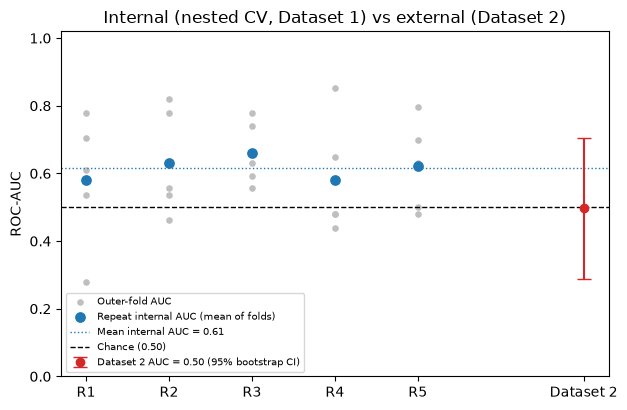

In [6]:
gap = internal.internal_auc - external["external_auc"]
repeats["gap_vs_external"] = repeats.internal_auc - external["external_auc"]
summary_table = pd.DataFrame({
    "internal (nested CV, mean of 5 repeats)": internal,
    "external (Dataset 2, Experiment 1 model)": pd.Series({"internal_auc": external["external_auc"],
        **{k: external[k] for k in ["balanced_accuracy", "sensitivity", "specificity", "accuracy"]}}),
}).rename(index={"internal_auc": "roc_auc"})
summary_table["internal − external"] = summary_table.iloc[:, 0] - summary_table.iloc[:, 1]
display(summary_table.round(3))
print(f"Generalization gap (AUC): {gap:+.3f}; absolute difference {abs(gap):.3f}")
print("Per-repeat gaps (split variability):", repeats.gap_vs_external.round(3).tolist())

fig, ax = plt.subplots(figsize=(6.4, 4.2))
for r in repeats.repeat:
    fold_aucs = folds.loc[folds.repeat == r, "outer_fold_auc"]
    ax.scatter(np.full(len(fold_aucs), r), fold_aucs, color="0.75", s=14, zorder=1,
               label="Outer-fold AUC" if r == 1 else None)
ax.scatter(repeats.repeat, repeats.internal_auc, color="tab:blue", s=45, zorder=2, label="Repeat internal AUC (mean of folds)")
ax.axhline(internal.internal_auc, color="tab:blue", lw=1, ls=":", label=f"Mean internal AUC = {internal.internal_auc:.2f}")
ax.errorbar([7], [external["external_auc"]], yerr=[[external["external_auc"] - external["ci_low"]],
            [external["ci_high"] - external["external_auc"]]], fmt="o", color="tab:red", capsize=5,
            label=f"Dataset 2 AUC = {external['external_auc']:.2f} (95% bootstrap CI)")
ax.axhline(0.5, color="k", lw=1, ls="--", label="Chance (0.50)")
ax.set_xticks([1, 2, 3, 4, 5, 7], ["R1", "R2", "R3", "R4", "R5", "Dataset 2"])
ax.set(ylabel="ROC-AUC", ylim=(0, 1.02), title="Internal (nested CV, Dataset 1) vs external (Dataset 2)")
ax.legend(fontsize=7, loc="lower left")
fig.tight_layout()
fig.savefig(OUTPUT / "internal_vs_external_auc.png", dpi=150)
plt.show()

## 6. Save outputs and summary

Only Dataset 2 has a confidence interval, which comes from Experiment 1's participant bootstrap. The internal spread is shown only as fold and repeat ranges.

In [7]:
oof.to_csv(OUTPUT / "nested_cv_outer_predictions.csv", index=False)
folds.to_csv(OUTPUT / "nested_cv_fold_metrics.csv", index=False)  # includes the settings chosen in each outer fold
repeats.to_csv(OUTPUT / "nested_cv_repeat_metrics.csv", index=False)
inner_scores_all.to_csv(OUTPUT / "nested_cv_inner_candidate_scores.csv", index=False)
summary_table.rename_axis("metric").to_csv(OUTPUT / "summary_metrics.csv")
experiment_1_selection_auc = json.loads(experiment_1_files["selected_settings.json"].read_text())["selected"]["primary_110"]["mean_cv_auc"]

settings = {
    "question": "Question 2: change from within-Dataset 1 (nested CV) to held-out Dataset 2 performance",
    "status": "exploratory follow-up; Dataset 2 already examined in Experiment 1",
    "features": FEATURES, "label_codes": LABEL_CODES,
    "pipeline": "StandardScaler -> LogisticRegression(l1_ratio=0.0 [L2], solver='lbfgs', max_iter=1000, C, class_weight)",
    "grid": {"C": C_VALUES, "class_weight": [str(w) for w in CLASS_WEIGHTS]},
    "selection_rule": "highest mean inner 5-fold ROC-AUC (rounded to 10 decimals); ties -> smaller C, then class_weight None",
    "outer_cv": f"StratifiedKFold(n_splits={N_FOLDS}, shuffle=True) repeated with seeds {OUTER_SEEDS}",
    "inner_cv": f"StratifiedKFold(n_splits={N_FOLDS}, shuffle=True, random_state=<repeat seed>) within outer training split",
    "threshold": THRESHOLD,
    "internal_summary": "repeat AUC = mean of 5 outer-fold AUCs; threshold metrics from each repeat's out-of-fold predictions; mean over repeats",
    "gap_definition": "mean nested-CV internal AUC - Dataset 2 AUC (positive = lower external performance)",
    "results": {"internal_auc": internal.internal_auc, "external_auc": external["external_auc"],
                "external_ci": [external["ci_low"], external["ci_high"]], "gap": gap,
                "experiment_1_selection_auc_not_an_internal_estimate": experiment_1_selection_auc},
    "input_sha256": input_hashes,
    "versions": {"python": platform.python_version(),
                 **{p: version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib"]}},
}
(OUTPUT / "experiment_settings.json").write_text(json.dumps(settings, indent=2, default=float) + "\n")

direction = ("lower on Dataset 2 than internally" if gap > 0 else "higher on Dataset 2 than internally" if gap < 0
             else "the same internally and on Dataset 2")
selected_counts = folds.groupby(["selected_C", "selected_class_weight"]).size()
text = "\n".join([
    "# Experiment 2 results summary", "",
    "Question 2: how much does performance change from within Dataset 1 (nested cross-validation) to held-out Dataset 2?", "",
    f"- Internal ROC-AUC (nested CV, mean of 5 repeats × 5 folds): {internal.internal_auc:.3f}. "
    f"Repeat AUCs ranged {repeats.internal_auc.min():.3f}–{repeats.internal_auc.max():.3f}; "
    f"single outer folds ranged {folds.outer_fold_auc.min():.3f}–{folds.outer_fold_auc.max():.3f} (split variability, not a CI).",
    f"- External ROC-AUC (Dataset 2, Experiment 1 model): {external['external_auc']:.3f} "
    f"(95% bootstrap CI {external['ci_low']:.3f}–{external['ci_high']:.3f}).",
    f"- Generalization gap (internal − external): {gap:+.3f}, i.e. performance was {direction}. "
    f"Per-repeat gaps: {', '.join(f'{g:+.3f}' for g in repeats.gap_vs_external)}.",
    f"- Balanced accuracy at 0.50: internal {internal.balanced_accuracy:.3f} vs external {external['balanced_accuracy']:.3f}; "
    f"sensitivity {internal.sensitivity:.3f} vs {external['sensitivity']:.3f}; "
    f"specificity {internal.specificity:.3f} vs {external['specificity']:.3f}.",
    f"- Settings chosen in the 25 outer folds: " + ", ".join(f"C={c:g}/{w}: {n}" for (c, w), n in selected_counts.items()) + ".",
    f"- For context only: Experiment 1's selection score ({experiment_1_selection_auc:.3f}) is optimistic and is not the internal estimate.", "",
    "## Interpretation and limits",
    "- Descriptive only: no significance test, because folds overlap and model selection adds uncertainty that the fold spread does not capture.",
    f"- The internal mean ({internal.internal_auc:.3f}) lies {'inside' if external['ci_low'] <= internal.internal_auc <= external['ci_high'] else 'outside'} "
    "the external 95% interval, so the size of the gap is very imprecise.",
    "- Outer-fold models train on ~60 participants; the external model on all 75. This compares a procedure, not one fitted model.",
    "- Sample composition, size, acquisition and exclusions (8.5% vs 42.6%) all differ between datasets; no single cause can be isolated.",
    "- Dataset 2 was already examined, so this is exploratory. Person-level independence is unconfirmed; Dataset 1 includes ten acquisition-2 participants.",
    "- Small samples (75 internal, 35 external), so all estimates are imprecise. Not a clinical tool.",
])
(OUTPUT / "results_summary.md").write_text(text + "\n")
display(Markdown(text))

# Experiment 2 results summary

Question 2: how much does performance change from within Dataset 1 (nested cross-validation) to held-out Dataset 2?

- Internal ROC-AUC (nested CV, mean of 5 repeats × 5 folds): 0.615. Repeat AUCs ranged 0.581–0.659; single outer folds ranged 0.280–0.852 (split variability, not a CI).
- External ROC-AUC (Dataset 2, Experiment 1 model): 0.497 (95% bootstrap CI 0.289–0.704).
- Generalization gap (internal − external): +0.118, i.e. performance was lower on Dataset 2 than internally. Per-repeat gaps: +0.085, +0.134, +0.163, +0.084, +0.125.
- Balanced accuracy at 0.50: internal 0.555 vs external 0.548; sensitivity 0.778 vs 0.952; specificity 0.331 vs 0.143.
- Settings chosen in the 25 outer folds: C=0.1/None: 9, C=0.1/balanced: 3, C=1/None: 6, C=1/balanced: 2, C=10/None: 3, C=10/balanced: 2.
- For context only: Experiment 1's selection score (0.635) is optimistic and is not the internal estimate.

## Interpretation and limits
- Descriptive only: no significance test, because folds overlap and model selection adds uncertainty that the fold spread does not capture.
- The internal mean (0.615) lies inside the external 95% interval, so the size of the gap is very imprecise.
- Outer-fold models train on ~60 participants; the external model on all 75. This compares a procedure, not one fitted model.
- Sample composition, size, acquisition and exclusions (8.5% vs 42.6%) all differ between datasets; no single cause can be isolated.
- Dataset 2 was already examined, so this is exploratory. Person-level independence is unconfirmed; Dataset 1 includes ten acquisition-2 participants.
- Small samples (75 internal, 35 external), so all estimates are imprecise. Not a clinical tool.